In [3]:
# Dependencias: instala PuLP 3 con el solver CBC, Matplotlib y NetworkX en el kernel del notebook.
%pip install --quiet "pulp>=3,<4" matplotlib networkx

Note: you may need to restart the kernel to use updated packages.


Estado Dual: Optimal
Objetivo dual óptimo (W*): 17
Capacidad del corte mínimo: 17
Particiones: S = ['A', 'B', 's'] | T = ['t']

Partición de nodos (p < 0.5: S; p >= 0.5: T):
Nodo s: p = 0 -> Lado S (Fuente)
Nodo A: p = 0 -> Lado S (Fuente)
Nodo B: p = 0 -> Lado S (Fuente)
Nodo t: p = 1 -> Lado T (Sumidero)

Arcos del corte mínimo (S -> T):
Arco ('A', 't'): capacidad = 8, d = 1
Arco ('B', 't'): capacidad = 9, d = 1
Capacidad total: 8 + 9 = 17


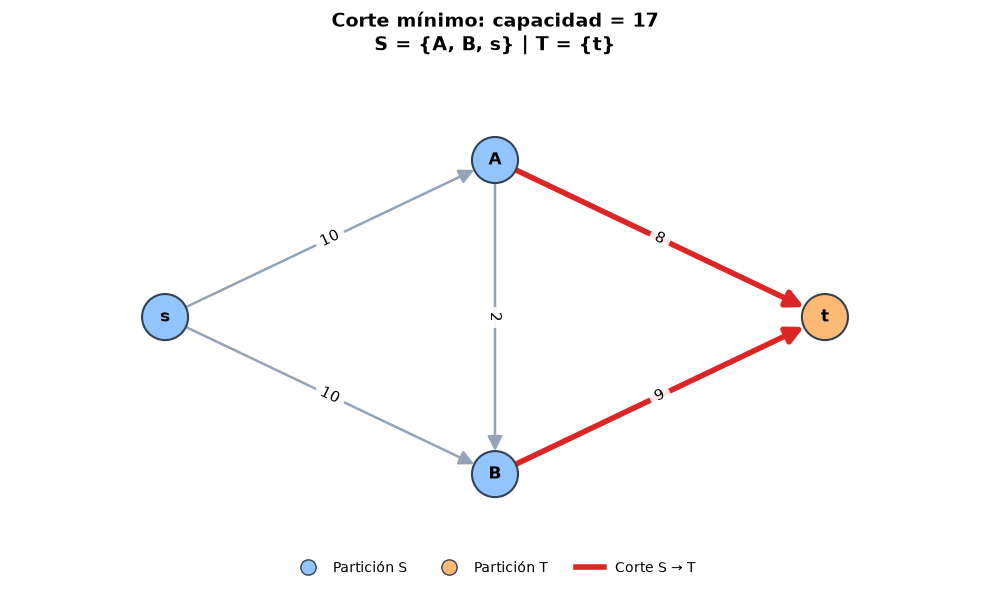

In [1]:
import pulp
# Importa las herramientas para construir y dibujar el grafo del corte.
import networkx as nx
import matplotlib.pyplot as plt
# Permite comprobar la igualdad numérica entre el objetivo y la capacidad del corte.
from math import isclose
# Permite crear la leyenda de las particiones y los arcos cortados.
from matplotlib.lines import Line2D

# 1. Definir el problema Dual de Minimización
dual_prob = pulp.LpProblem("Corte_Minimo_Dual", pulp.LpMinimize)

nodes = ['s', 'A', 'B', 't']
capacities = {
    ('s', 'A'): 10,
    ('s', 'B'): 10,
    ('A', 'B'): 2,
    ('A', 't'): 8,
    ('B', 't'): 9
}

# 2. Variables continuas relajadas [0, 1]
p = {i: pulp.LpVariable(f"p_{i}", lowBound=0, upBound=1, cat='Continuous') for i in nodes}
d = {e: pulp.LpVariable(f"d_{e[0]}_{e[1]}", lowBound=0, upBound=1, cat='Continuous') for e in capacities}

# 3. Función Objetivo: Minimizar capacidad del corte
dual_prob += pulp.lpSum([capacities[e] * d[e] for e in capacities])

# 4. Restricciones de separación y anclaje
for (u, v) in capacities:
    # Con p[s]=0 y p[t]=1, un arco S → T exige d[u,v] >= p[v] - p[u].
    dual_prob += d[(u, v)] + p[u] - p[v] >= 0, f"Corte_Arco_{u}_{v}"

dual_prob += p['s'] == 0, "Anclaje_Fuente"
dual_prob += p['t'] == 1, "Anclaje_Sumidero"

# 5. Resolver el modelo continuo con CBC
dual_prob.solve(pulp.PULP_CBC_CMD(msg=0))

# Comprueba que el modelo tenga un óptimo antes de consultar las variables.
if dual_prob.status != pulp.LpStatusOptimal:
    raise RuntimeError(f"No se obtuvo un corte mínimo: {pulp.LpStatus[dual_prob.status]}")

# Recupera el valor de la función objetivo del modelo dual.
valor_dual = pulp.value(dual_prob.objective)
# Extrae una partición de las variables continuas usando el mismo umbral para todos los nodos.
S = {nodo for nodo in nodes if p[nodo].varValue < 0.5}
# Asigna a T todos los nodos restantes, incluido el sumidero.
T = set(nodes) - S
# Selecciona solo los arcos originales que salen de S y entran en T.
arcos_corte = [(u, v) for u, v in capacities if u in S and v in T]
# Suma las capacidades originales de los arcos S → T; los arcos T → S no cuentan.
capacidad_corte_minimo = sum(capacities[e] for e in arcos_corte)
# Verifica que la partición separe correctamente la fuente del sumidero.
if 's' not in S or 't' not in T:
    raise RuntimeError("La partición no separa la fuente s del sumidero t.")
# Comprueba que el corte extraído alcance el mismo valor mínimo que el modelo dual.
if not isclose(capacidad_corte_minimo, valor_dual, rel_tol=1e-7, abs_tol=1e-7):
    raise RuntimeError("La capacidad del corte extraído no coincide con el objetivo dual.")

print(f"Estado Dual: {pulp.LpStatus[dual_prob.status]}")
print(f"Objetivo dual óptimo (W*): {valor_dual:g}")
print(f"Capacidad del corte mínimo: {capacidad_corte_minimo:g}")
print(f"Particiones: S = {sorted(S)} | T = {sorted(T)}")
print("\nPartición de nodos (p < 0.5: S; p >= 0.5: T):")
for nodo in nodes:
    lado = "S (Fuente)" if nodo in S else "T (Sumidero)"
    print(f"Nodo {nodo}: p = {p[nodo].varValue:g} -> Lado {lado}")

# Informa los arcos de la partición real en lugar de decidir el corte solo por d.
print("\nArcos del corte mínimo (S -> T):")
for e in arcos_corte:
    print(f"Arco {e}: capacidad = {capacities[e]:g}, d = {d[e].varValue:g}")
# Muestra la suma que produce la capacidad del corte, incluso si el corte no contiene arcos.
suma_capacidades = " + ".join(f"{capacities[e]:g}" for e in arcos_corte) or "0"
print(f"Capacidad total: {suma_capacidades} = {capacidad_corte_minimo:g}")

# Construye el grafo con los mismos nodos, capacidades y particiones del modelo dual.
G = nx.DiGraph()
G.add_nodes_from(nodes)
# Conserva en cada arco su capacidad original y si pertenece al corte calculado.
for u, v in capacities:
    G.add_edge(u, v, capacity=capacities[(u, v)], cortado=(u, v) in arcos_corte)

# Fija posiciones para distinguir visualmente la fuente, los nodos intermedios y el sumidero.
pos = {'s': (0, 1), 'A': (1, 2), 'B': (1, 0), 't': (2, 1)}
# Identifica cada arco con su capacidad original.
etiquetas_arcos = {e: f"{capacities[e]:g}" for e in capacities}
# Colorea los nodos de S en azul y los de T en naranja.
colores_nodos = ['#93c5fd' if nodo in S else '#fdba74' for nodo in G.nodes]
# Separa los arcos que no cruzan de S hacia T para dibujarlos en gris.
arcos_restantes = [e for e in capacities if e not in arcos_corte]
# Crea la figura del corte en la misma celda que calcula el óptimo.
fig_corte, ax_corte = plt.subplots(figsize=(10, 6))
# Dibuja los nodos según la partición obtenida de las variables p.
nx.draw_networkx_nodes(
    G, pos, ax=ax_corte, node_size=1100, node_color=colores_nodos,
    edgecolors='#334155', linewidths=1.5)
# Muestra los arcos que no forman parte del corte con menor grosor.
nx.draw_networkx_edges(
    G, pos, ax=ax_corte, edgelist=arcos_restantes, edge_color='#94a3b8',
    width=1.8, arrowstyle='-|>', arrowsize=22, node_size=1100)
# Resalta en rojo los arcos S → T cuyas capacidades se sumaron.
nx.draw_networkx_edges(
    G, pos, ax=ax_corte, edgelist=arcos_corte, edge_color='#dc2626',
    width=4, arrowstyle='-|>', arrowsize=25, node_size=1100)
# Escribe los nombres de los nodos.
nx.draw_networkx_labels(G, pos, ax=ax_corte, font_size=12, font_weight='bold')
# Muestra las capacidades sobre las flechas del grafo.
nx.draw_networkx_edge_labels(
    G, pos, ax=ax_corte, edge_labels=etiquetas_arcos, font_size=11,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.9))
# Usa el resultado calculado, sin fijar manualmente la capacidad del corte.
ax_corte.set_title(
    f"Corte mínimo: capacidad = {capacidad_corte_minimo:g}\n"
    f"S = {{{', '.join(sorted(S))}}} | T = {{{', '.join(sorted(T))}}}",
    fontsize=14, fontweight='bold', pad=18)
ax_corte.margins(0.20)
ax_corte.axis('off')
# Explica los colores de las particiones y el sentido de los arcos que aportan a la capacidad.
ax_corte.legend(handles=[
    Line2D([], [], marker='o', linestyle='None', markersize=11,
           markerfacecolor='#93c5fd', markeredgecolor='#334155', label='Partición S'),
    Line2D([], [], marker='o', linestyle='None', markersize=11,
           markerfacecolor='#fdba74', markeredgecolor='#334155', label='Partición T'),
    Line2D([], [], color='#dc2626', linewidth=4, label='Corte S → T'),
], loc='lower center', bbox_to_anchor=(0.5, -0.06), ncol=3, frameon=False)
# Ajusta los espacios del título y la leyenda.
fig_corte.tight_layout()
# Muestra el grafo al ejecutar esta misma celda del modelo dual.
plt.show()
